### In this Section, we loaded the housing dataset using Pandas and display the first five data points. We also added added necessary libraries that we will be using for later on in the code. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("Housing.csv")
df.head()

,Size,Bedrooms,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


### We use df.shape to determine the number of rows and columns within the dataset. The dataset tells us about having 47 observations with three columns representing the size, number of bedrooms and price

In [2]:
df.shape

(47, 3)

### In this section, we scaled the features and set them to zero mean. We separated the X variable into Size and Bedrooms and the y variable into price. Next we calculated the mean from each value and divided by its corresponding standard deviation. 

In [3]:
X=df[['Size','Bedrooms']].values
y=df['Price'].values

mu= np.mean(X, axis=0)
sigma= np.std(X, axis=0)

X_norm = (X - mu)/(sigma)

### After normalizing the features, we displayed the normalized data points to see the changes made to the original dataset. 

In [4]:
X_norm

array([[ 1.31415422e-01, -2.26093368e-01],
       [-5.09640698e-01, -2.26093368e-01],
       [ 5.07908699e-01, -2.26093368e-01],
       [-7.43677059e-01, -1.55439190e+00],
       [ 1.27107075e+00,  1.10220517e+00],
       [-1.99450507e-02,  1.10220517e+00],
       [-5.93588523e-01, -2.26093368e-01],
       [-7.29685755e-01, -2.26093368e-01],
       [-7.89466782e-01, -2.26093368e-01],
       [-6.44465993e-01, -2.26093368e-01],
       [-7.71822042e-02,  1.10220517e+00],
       [-8.65999486e-04, -2.26093368e-01],
       [-1.40779041e-01, -2.26093368e-01],
       [ 3.15099326e+00,  2.43050370e+00],
       [-9.31923697e-01, -2.26093368e-01],
       [ 3.80715024e-01,  1.10220517e+00],
       [-8.65782986e-01, -1.55439190e+00],
       [-9.72625673e-01, -2.26093368e-01],
       [ 7.73743478e-01,  1.10220517e+00],
       [ 1.31050078e+00,  1.10220517e+00],
       [-2.97227261e-01, -2.26093368e-01],
       [-1.43322915e-01, -1.55439190e+00],
       [-5.04552951e-01, -2.26093368e-01],
       [-4.

### In this section we initialized the three theta parameters before running gradient descent. First determining the number of training examples and adding a column of ones to the normalized feature matrix.
### The three parameters are initialized to zero and will be updated during gradient descent to determine their values for the linear regression model

In [5]:
m = len(y)

X_b = np.c_[np.ones((m,1)), X_norm]

theta = np.zeros(3)

X_b.shape

(47, 3)

In [6]:
theta

array([0., 0., 0.])

### In this section, we implemented batch gradient descent using 1500 iterations and a learning rate of 0.01. During each iteration, we calculate the gradients, update and save the three theta values, and calculate the cost using the prediction errors. 

In [7]:
n_iterations = 1500
alpha = 0.01

theta_history = []
J_history = []

for i in range(n_iterations):
    predictions = X_b.dot(theta)

    gradients = (1/m) * X_b.T.dot(predictions - y)

    theta = theta - alpha * gradients

    theta_history.append(theta.copy())

    errors = X_b.dot(theta) - y
    J = (1/(2*m)) * np.sum(errors**2)

    J_history.append(J)

### After completing gradient descent, we display the three final theta values. We also examine the initial and final costs to observe how much the cost has decreased from the 1500 iterations. 

In [8]:
theta

array([340412.56301439, 109370.05670466,  -6500.61509507])

In [9]:
J_history[0]

np.float64(64297776251.6201)

In [10]:
J_history[-1]

np.float64(2043282709.9327548)

In [11]:
len(J_history)

1500

### This section is solely used to plot the convergence graph using the cost values saved during our gradient descent calculations. This displays the number of iterations on the horizontal axis, and the cost on the vertical axis.

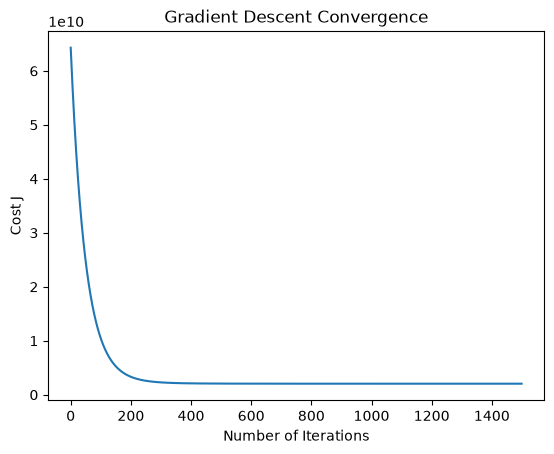

In [12]:
plt.plot(range(n_iterations), J_history)
plt.xlabel("Number of Iterations")
plt.ylabel("Cost J")
plt.title("Gradient Descent Convergence")
plt.show()

### In this section, we use the final theta values from gradient descent to estimate the price of a house with 1650 square feet and 3 bedrooms. We normalize these values using the same mean and standard deviation from our dataset before calculating the predicted price. 

In [13]:
house = np.array([1650, 3])
house_norm = (house - mu) / sigma

house_b = np.r_[1, house_norm]
predicted_price = house_b.dot(theta)

print("Predicted house price:", predicted_price)

Predicted house price: 293098.4666757651
